# LeetCode #91: Decode Ways

https://leetcode.com/problems/decode-ways/

## Three ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute force: try every split** | $O(2^n)$ | $O(n)$ | 100 ones have about $5.7 \times 10^{20}$ decodings. Listing them one at a time never finishes. |
| **A table of counts** | $O(n)$ | $O(n)$ | 100 digits is about 100 small steps, plus a list of 101 numbers. |
| **Two running counts ★** | $O(n)$ | $O(1)$ | The same 100 steps, but only two numbers are kept. |

`n` is the number of digits. $O(n)$ means **the work grows in step with the length**: twice the digits,
twice the steps. $O(1)$ means the memory stays the same however long the string is. $O(2^n)$ means each
extra digit can roughly double the work.

Letters are coded `A = 1` to `Z = 26`. **Decoding** means splitting the digit string into pieces that
are each one of those codes. A piece can't start with `0`: `"06"` is not F.

## Understanding the methods

### Brute force

At each position, take one digit or two digits as the next letter, and recurse on the rest. The same
tail of the string gets decoded again for every different way of reading the front, so the calls pile up
exponentially.

### A table of counts

Let `ways[k]` be the number of ways to decode the first `k` digits. The last letter used either digit
`k` alone (allowed unless it's a `0`) or digits `k-1` and `k` together (allowed if they make 10 to 26). So
`ways[k]` is `ways[k-1]` plus `ways[k-2]`, each counted only if its check passes. Building each answer
from smaller answers that are already stored is called **dynamic programming**.

### Optimal: two running counts ★ (the one coded below)

`ways[k]` only ever reads the two boxes just before it. So keep those two in variables, `prev2` and
`prev1`, and slide them forward one digit at a time instead of keeping the whole table.

**Why this beats the table:** the same steps in the same order, but the memory no longer grows with the
string.

**Constraints:**
* `1 <= s.length <= 100`
* `s` contains only digits and may contain leading zero(s)
* The answer is guaranteed to fit in a 32-bit integer


## Explain Like I'm a Newbie

### What the question is actually asking

Someone wrote a message as numbers, `A = 1` up to `Z = 26`, and the spaces got lost. Given only the
digits, how many different messages could it have been?

```
"226"  ->  2 2 6   (B B F)
           22 6    (V F)
           2 26    (B Z)        3 ways
```

A piece can never start with a zero. `"0"` alone isn't a letter, and `"06"` isn't F.

### The one idea you need: look at how the message ends

Listing every split explodes: 100 ones have more than $10^{20}$ of them. So don't list, count. Think
about the **last letter** of any decoding. It used either the last digit on its own, or the last two
digits together. There is no third option. That gives the sentence the whole solution rests on:

> **`ways[k]` = the number of ways to decode the first `k` digits.** It's `ways[k-1]` (if digit `k`
> alone is a letter) plus `ways[k-2]` (if digits `k-1` and `k` together are a letter).

Start with `ways[0] = 1`: an empty string has exactly one decoding, the empty message. That 1 is what
lets `"26"` count as Z.

### What that means in code

Walk left to right. Each step only needs the two previous counts, so keep two variables: `prev1` is
`ways[k-1]` and `prev2` is `ways[k-2]`, and shift them along after every digit. Filling answers from
smaller ones like this is **dynamic programming**. It has the same shape as Fibonacci, except two checks
can switch either term off, and the checks are where the bugs live:

- one digit counts only if it isn't `'0'`;
- two digits count only if they're **between 10 and 26**. `int("06")` is 6, which is under 26, but a
  code can't start with 0.

### Mistakes people make the first time

1. **Checking only `<= 26` for the pair.** It passes all three of LeetCode's samples (`"12"`, `"226"`,
   `"06"`). On `"106"` it returns 2 instead of 1, because it reads `"06"` as F.
2. **Always adding the one-digit count.** Also passes all three samples, since `"06"` is caught by the
   early return. On `"10"` it answers 2 instead of 1, treating the lone 0 as a letter.
3. **Starting `prev2` at 0.** A pair at the very start then adds nothing, and `"12"` answers 1.
4. **Dropping the leading-zero check.** `"06"` then answers 1.

### Things worth knowing

A zero has to glue onto a 1 or 2 just before it, so `"30"` or `"00"` anywhere makes the answer 0. And
the counts in the middle can be far bigger than the final answer: sixty ones followed by `"30"` answers 0,
but passes through about 4 trillion on the way.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Count by the last letter. The first k digits end either with digit k on its own, which works unless it's a zero, or with the last two digits as one letter, which works if they make 10 to 26. So ways[k] is ways[k−1] plus ways[k−2], each switched on or off by its check, with ways[0] = 1 for the empty prefix. That only reads two numbers back, so I keep two variables. O(n) time, O(1) space. The character to watch is the zero, which fails both checks unless a 1 or 2 sits right before it."

The recurrence, both guards, the base case, and the one character that makes this harder than Fibonacci. That's the whole problem in four sentences.

---

### I slide the problem across the table

I write `"226"` and the mapping `A = 1` to `Z = 26`, and ask how many ways it decodes.

> **You:** "2-2-6, 22-6 and 2-26, so three. Can the string contain zeros, and can it start with one?"

**"Yes to both. `"06"` has no decodings: there's no letter for 0, and `06` isn't a valid code."** That's the question I'm waiting for. Every bug in this problem lives in the zeros, and a candidate who doesn't ask usually ends up counting `06` as F.

> **You:** "How big can the answer get? A hundred ones would be Fibonacci-sized."

**"Up to 100 digits, and the answer is guaranteed to fit in 32 bits."** Good. You've noticed the count grows exponentially. I'll come back to exactly what that guarantee covers.

---

### Now tell me what's actually hard about it

> **You:** "Trying every split is correct but explodes. Each position offers up to two choices, so a hundred ones has more than 10 to the 20 decodings. And it repeats itself: the decodings of the last 90 digits get rebuilt for every way of reading the first ten."

> **You:** "So I shouldn't list them, I should count them. Every decoding ends with a last letter, and that letter is either the last digit alone or the last two together. If I already know how many ways the two shorter prefixes have, I just add them."

That's the difficulty named first, repeated work on an exponential count, and the fix falling straight out of it. Nobody has said "dynamic programming" yet, and nobody needed to.

I usually push here: "what about `"10"`?"

> **You:** "The 0 alone isn't a letter, so that term is zero. `10` together is J, so it takes ways[0], which is one. One decoding. And `"30"` fails both checks, so from there on every count is zero."

---

### Before you touch the board, tell me the shape and the cost

> **You:** "ways[k] is the number of ways to decode the first k digits. ways[0] is 1, ways[1] is 1 if the first digit isn't zero. For each later digit I add ways[k−1] if it isn't '0', and ways[k−2] if the last two digits make 10 to 26.
>
> One pass, a constant amount of work per digit, so 100 digits is about 100 steps. The table would hold 101 numbers, but each entry only looks two back, so two variables do the same job."

The cost comes from the shape of the loop, not from memory. And I like hearing "ways[k] means..." out loud. Candidates who can't say what a box in the table means are guessing the recurrence.

---

### Now whiteboard it

```
if s[0] == '0':
    return 0
prev2, prev1 = 1, 1
```

> **You:** "A leading zero can't start any letter, so nothing decodes. prev2 stands for ways[0], the empty prefix. It's 1, not 0, because that's what lets a pair at the very start count."

If you write `prev2 = 0` and say nothing, I'll ask you to run `"12"`. It comes out 1.

```
for i in range(1, len(s)):
    curr = 0
    if s[i] != '0':
        curr += prev1
```

> **You:** "Digit i on its own ends the message. Every decoding of everything before it still works, unless this digit is a zero."

```
    two_digit = int(s[i - 1:i + 1])
    if 10 <= two_digit <= 26:
        curr += prev2
    prev2, prev1 = prev1, curr
return prev1
```

> **You:** "The lower bound matters as much as the upper one. `06` parses as 6, which is under 26, but a code can't start with 0. Then both counts shift forward together."

The 10 is the line I watch. Without it, all three of LeetCode's samples still pass, and `"106"` answers 2.

---

### Walk me through it before you say you're done

> **You:** "On `"11106"`. ways[0] = 1, ways[1] = 1. Second 1: alone gives 1, `11` gives 1, so 2. Third 1: 2 plus 1, so 3. The 0: alone it's nothing, `10` is J, so it takes ways[2], 2. The 6: alone takes 2, and `06` fails the 10 check. Answer 2: AAJF and KJF."

> **You:** "And `"06"`, from your zeros question: the early return gives 0 before the loop starts."

Tying the dry-run back to the clarifier is exactly what I want.

---

### Then tell me where it breaks, before I ask

> **You:** "Time and memory are as good as they get: every digit has to be read once, and I keep two numbers. What it leans on is the size of the counts. Your guarantee covers the final answer, not the middle. Sixty ones followed by `30` answers 0, but passes through about 4 trillion on the way. Python doesn't care. In C# the int quietly wraps, and that's harmless here, because there are only additions: the final number comes out right modulo 2 to the 32, and the guarantee says it fits. Rust checks for overflow, so on an input like that it could panic. A wider type doesn't save you either: a hundred digits can push the middle past 64 bits. The clean fix is to make the additions wrap on purpose, `wrapping_add` in Rust."

That's a better answer than I usually get, and it's specific to this problem: you looked at what the guarantee actually promises.

If I push further, "now the string can contain `*`, meaning any digit 1 to 9":

> **You:** "Same two terms. The checks turn into counts: a `*` alone is 9 options, `1*` is 9 pairs, `2*` is 6. The numbers get huge, so I'd take everything modulo 10^9 + 7."

---

### What would worry me

Counting `06` as F. Starting prev2 at 0. Building every decoding in a list just to count them. And "it's basically Fibonacci" with nothing said about what a zero does to each of the two terms.


## Solutions

All four keep two counts, the ways to decode everything up to one digit back and two digits back, and add them as each digit allows.

### C#


In [ ]:
public class Solution {
    public int NumDecodings(string s) {
        // No letter's code starts with 0, so nothing can decode the first digit
        if (s[0] == '0') return 0;

        // ways[k] = ways to decode the first k digits. We only ever need the last two:
        // prev2 = ways[i-1], prev1 = ways[i]. prev2 starts at 1 for the EMPTY prefix,
        // which is what lets a pair at the very start (like "12") count.
        int prev2 = 1, prev1 = 1;

        for (int i = 1; i < s.Length; i++) {
            int curr = 0;

            // s[i] alone as the last letter: every decoding up to s[i-1] still works.
            // A lone '0' is not a letter.
            if (s[i] != '0') curr += prev1;

            // s[i-1..i] together as the last letter: every decoding up to s[i-2] works.
            // The >= 10 matters: "06" is 6, but a code can't start with 0.
            int twoDigit = (s[i - 1] - '0') * 10 + (s[i] - '0');
            if (twoDigit >= 10 && twoDigit <= 26) curr += prev2;

            // Slide both counts one digit forward
            prev2 = prev1;
            prev1 = curr;
        }

        return prev1;
    }
}

### Python


In [ ]:
class Solution:
    def numDecodings(self, s: str) -> int:
        # No letter's code starts with 0, so nothing can decode the first digit
        if s[0] == '0':
            return 0

        # ways[k] = ways to decode the first k digits. We only ever need the last two:
        # prev2 = ways[i-1], prev1 = ways[i]. prev2 starts at 1 for the EMPTY prefix,
        # which is what lets a pair at the very start (like "12") count.
        prev2, prev1 = 1, 1

        for i in range(1, len(s)):
            curr = 0

            # s[i] alone as the last letter: every decoding up to s[i-1] still works.
            # A lone '0' is not a letter.
            if s[i] != '0':
                curr += prev1

            # s[i-1..i] together as the last letter: every decoding up to s[i-2] works.
            # The >= 10 matters: int("06") is 6, but a code can't start with 0.
            two_digit = int(s[i - 1:i + 1])
            if 10 <= two_digit <= 26:
                curr += prev2

            # Slide both counts one digit forward
            prev2, prev1 = prev1, curr

        return prev1

### Go


In [ ]:
func numDecodings(s string) int {
    // No letter's code starts with 0, so nothing can decode the first digit
    if s[0] == '0' {
        return 0
    }

    // ways[k] = ways to decode the first k digits. We only ever need the last two:
    // prev2 = ways[i-1], prev1 = ways[i]. prev2 starts at 1 for the EMPTY prefix,
    // which is what lets a pair at the very start (like "12") count.
    prev2, prev1 := 1, 1

    for i := 1; i < len(s); i++ {
        curr := 0

        // s[i] alone as the last letter: every decoding up to s[i-1] still works.
        // A lone '0' is not a letter.
        if s[i] != '0' {
            curr += prev1
        }

        // s[i-1..i] together as the last letter: every decoding up to s[i-2] works.
        // The >= 10 matters: "06" is 6, but a code can't start with 0.
        twoDigit := int(s[i-1]-'0')*10 + int(s[i]-'0')
        if twoDigit >= 10 && twoDigit <= 26 {
            curr += prev2
        }

        // Slide both counts one digit forward
        prev2, prev1 = prev1, curr
    }

    return prev1
}

### Rust

Rust checks `+` for overflow in debug builds. The guarantee covers only the final answer, so an input like sixty `1`s followed by `30` (answer 0) pushes a count in the middle past `i32` and would panic there; `wrapping_add` would make that safe, because the final sum is still exact.


In [ ]:
impl Solution {
    pub fn num_decodings(s: String) -> i32 {
        let bytes = s.as_bytes();
        // No letter's code starts with 0, so nothing can decode the first digit
        if bytes[0] == b'0' { return 0; }

        // ways[k] = ways to decode the first k digits. We only ever need the last two:
        // prev2 = ways[i-1], prev1 = ways[i]. prev2 starts at 1 for the EMPTY prefix,
        // which is what lets a pair at the very start (like "12") count.
        let (mut prev2, mut prev1) = (1i32, 1i32);

        for i in 1..bytes.len() {
            let mut curr = 0;

            // s[i] alone as the last letter: every decoding up to s[i-1] still works.
            // A lone '0' is not a letter.
            if bytes[i] != b'0' { curr += prev1; }

            // s[i-1..i] together as the last letter: every decoding up to s[i-2] works.
            // The >= 10 matters: "06" is 6, but a code can't start with 0.
            let two_digit = (bytes[i - 1] - b'0') as i32 * 10 + (bytes[i] - b'0') as i32;
            if two_digit >= 10 && two_digit <= 26 { curr += prev2; }

            // Slide both counts one digit forward
            prev2 = prev1;
            prev1 = curr;
        }

        prev1
    }
}

## Example Scenarios

### 1. Common Case — LeetCode's "226"
**Input:** `s = "226"`

The counts go 1, 1, 2, 3. Every digit can stand alone and both `22` and `26` are letters, so each new box
adds both boxes before it. The three decodings are `2 2 6`, `22 6` and `2 26`. **Output:** `3`

### 2. Slightly Complex — A Leading Zero
**Input:** `s = "06"`

No letter is 0 and no code starts with 0, so the first digit can't be decoded at all and the function
returns 0 before the loop starts. `"06"` is not F. **Output:** `0`

### 3. Edge Case: Time Factor — 100 Digits, the Biggest Answer That Fits
**Input:** `s = "1" * 44 + "3" * 56` (100 digits)

The longest string allowed, so the loop runs all 99 steps. The ones grow the count like Fibonacci, the
`13` where they meet adds one more step, and after that each 3 can only stand alone (`33` isn't a letter),
so the count freezes at the largest Fibonacci number under $2^{31}$. **Output:** `1836311903`

### 4. Edge Case: Space Factor — "10" (Memory Never Grows)
**Input:** `s = "10"`

This solution keeps two numbers for every input, so no input is harder on memory than another; this one
just shows the zero rule. The 0 alone adds nothing, and `10` together is J, which takes `ways[0] = 1`.
**Output:** `1`

### 5. Almost-Impossible but Plausible — A Zero in the Middle
**Input:** `s = "2101"`

`21` can be read two ways, but the 0 has to glue onto the 1 just before it, so both readings collapse into
one: `2 10 1`. The counts go 1, 1, 2, 1, 1. **Output:** `1`


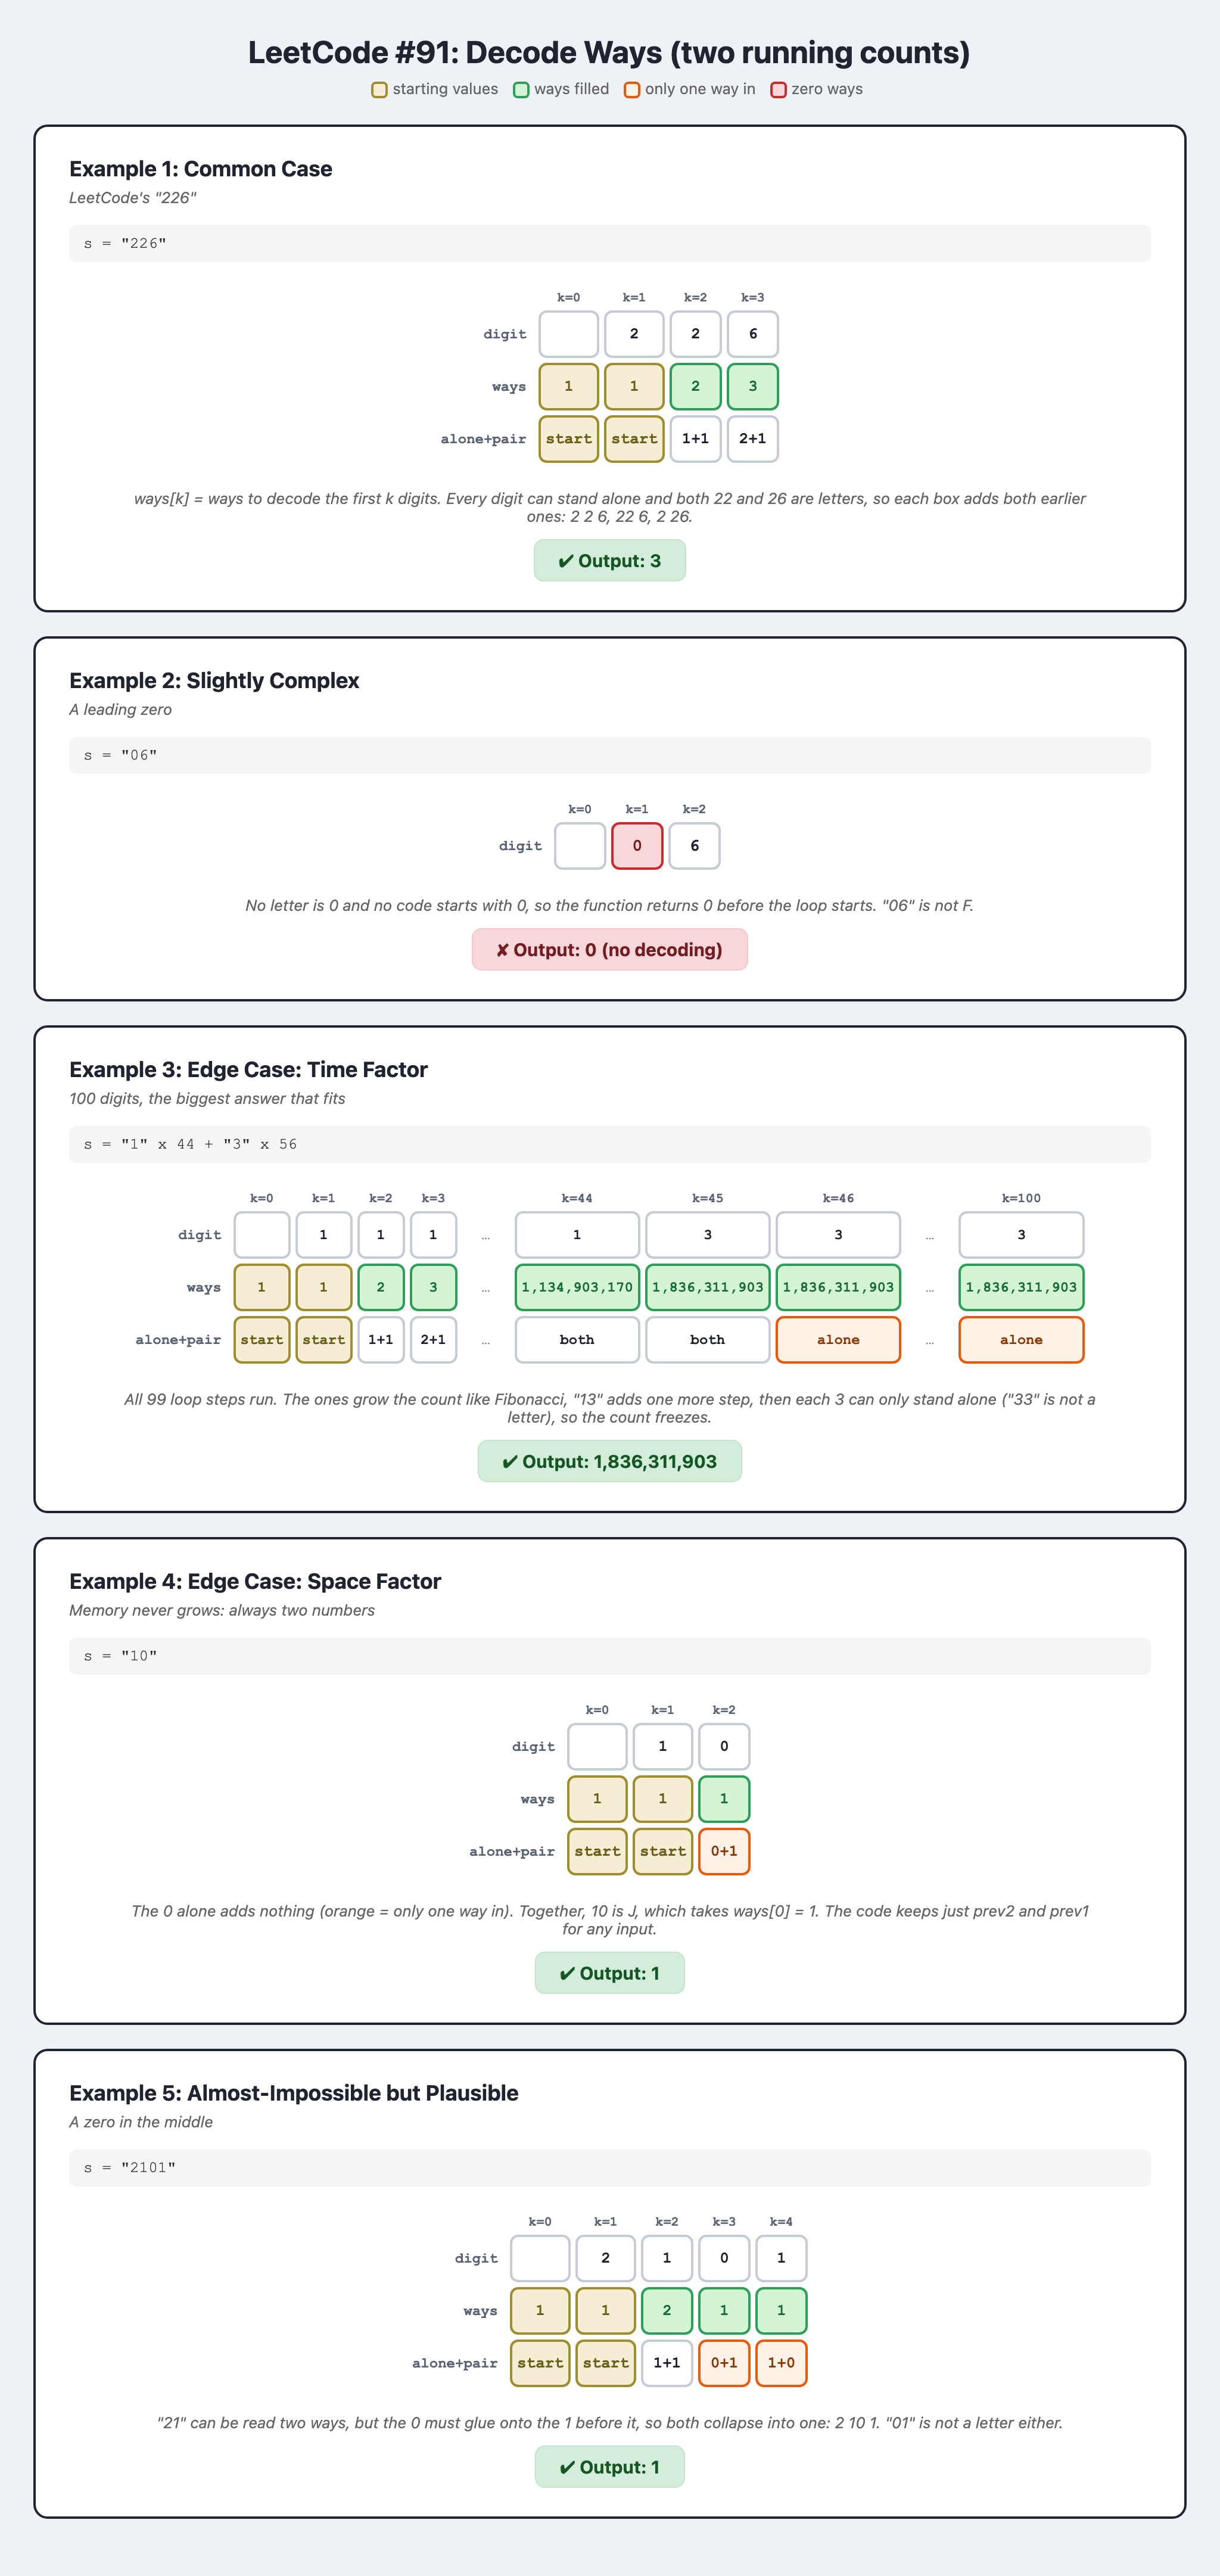

## Watch It Run

*Watch the zero at k=4: read alone it's not a letter, so the only way in is as the pair 10, and then 06 is rejected too.*

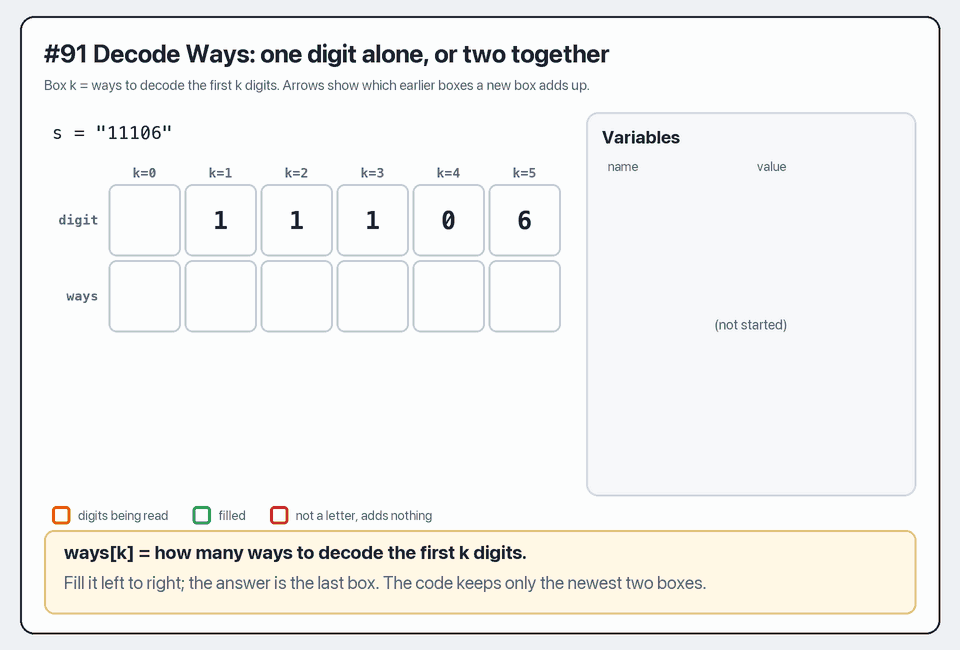

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0091.html)**